# **Sales Prediction Model Using Machine Learning**

## Project Overview

Sales prediction is an important business analytics technique that helps organizations estimate future sales based on available data. Accurate predictions can support advertising decisions, budgeting, and business planning.

## Objective

The objective of this project is to predict sales using advertising expenditure across TV, radio, and newspaper channels. Linear Regression and Random Forest Regression are trained and evaluated to compare their predictive performance.

## Dataset

This project uses the Advertising dataset, which contains 200 observations with advertising expenditure for TV, radio, and newspaper, along with the corresponding sales values.

## Tools and Technologies

* Python
* Pandas and NumPy
* Matplotlib and Seaborn
* Scikit-learn
* Google Colab


## 1. Importing Libraries

This project uses Python libraries for data analysis, numerical calculations, and visualization.

* **Pandas:** Used to load, organize, and analyze the advertising dataset.
* **NumPy:** Supports numerical operations and calculations.
* **Matplotlib:** Used to create graphs and visualize model results.
* **Seaborn:** Helps create statistical visualizations and explore relationships between advertising expenditure and sales.

These libraries provide the foundation for exploring the dataset and understanding the relationship between advertising expenditure and sales.


In [42]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("Libraries imported successfully!")

Libraries imported successfully!


## 2. Loading the Dataset

This project uses the Advertising dataset to study the relationship between advertising expenditure and sales.

The dataset contains four columns:

* **TV:** Advertising expenditure on TV.
* **Radio:** Advertising expenditure on radio.
* **Newspaper:** Advertising expenditure on newspapers.
* **Sales:** Sales associated with the advertising expenditure.

The dataset is loaded into a Pandas DataFrame using `pd.read_csv()`. This allows us to inspect, analyze, and prepare the data for machine learning.


In [43]:
df = pd.read_csv('/content/advertising.csv')

print("Dataset loaded successfully!")

Dataset loaded successfully!


## 3. Initial Data Inspection

After loading the dataset, we inspect its structure, completeness, and statistical properties to understand the available information.

The following operations help us examine the data:

* **First Five Rows (`df.head()`):** Displays the first five rows to understand how the data is organized.
* **Dataset Shape (`df.shape`):** Identifies the number of rows and columns.
* **Dataset Information (`df.info()`):** Shows column data types and non-null values.
* **Missing Values (`df.isnull().sum()`):** Checks for missing values in each column.
* **Summary Statistics (`df.describe()`):** Provides statistical measures such as mean, standard deviation, minimum, maximum, and quartiles.
* **Duplicate Records (`df.duplicated().sum()`):** Checks for duplicate rows in the dataset.

The dataset contains 200 rows and 4 columns, with no missing values or duplicate rows. These checks help confirm the dataset's quality before further analysis and model training.


In [44]:
df.head()

,TV,Radio,Newspaper,Sales
0,230.1,37.8,69.2,22.1
1,44.5,39.3,45.1,10.4
2,17.2,45.9,69.3,12.0
3,151.5,41.3,58.5,16.5
4,180.8,10.8,58.4,17.9


In [45]:
print("Dataset shape:", df.shape)

Dataset shape: (200, 4)


In [46]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 4 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   TV         200 non-null    float64
 1   Radio      200 non-null    float64
 2   Newspaper  200 non-null    float64
 3   Sales      200 non-null    float64
dtypes: float64(4)
memory usage: 6.4 KB


In [47]:
print(df.isnull().sum())

TV           0
Radio        0
Newspaper    0
Sales        0
dtype: int64


In [48]:
df.describe()

,TV,Radio,Newspaper,Sales
count,200.000000,200.000000,200.000000,200.000000
mean,147.042500,23.264000,30.554000,15.130500
std,85.854236,14.846809,21.778621,5.283892
min,0.700000,0.000000,0.300000,1.600000
25%,74.375000,9.975000,12.750000,11.000000
50%,149.750000,22.900000,25.750000,16.000000
75%,218.825000,36.525000,45.100000,19.050000
max,296.400000,49.600000,114.000000,27.000000


In [49]:
print("Number of duplicate rows:", df.duplicated().sum())

Number of duplicate rows: 0


## 4. Exploratory Data Analysis (EDA)

Exploratory Data Analysis helps us understand patterns and relationships in the advertising dataset before building machine learning models.

### Advertising Data Visualization

The following visualizations examine how advertising expenditure relates to sales:

* **TV Advertising vs. Sales:** Shows a strong positive relationship between TV advertising expenditure and sales.
* **Radio Advertising vs. Sales:** Helps examine the relationship between radio advertising expenditure and sales.
* **Newspaper Advertising vs. Sales:** Helps determine whether newspaper advertising expenditure is associated with sales.
* **Correlation Heatmap:** Displays the correlations between TV, radio, newspaper, and sales.

### Key Observation

The correlation heatmap shows that TV advertising has the strongest positive correlation with sales (0.90). Radio has a weaker positive correlation (0.35), while newspaper has a relatively weak correlation (0.16).

These visualizations help us understand the data and identify relationships that may be useful for predicting sales.


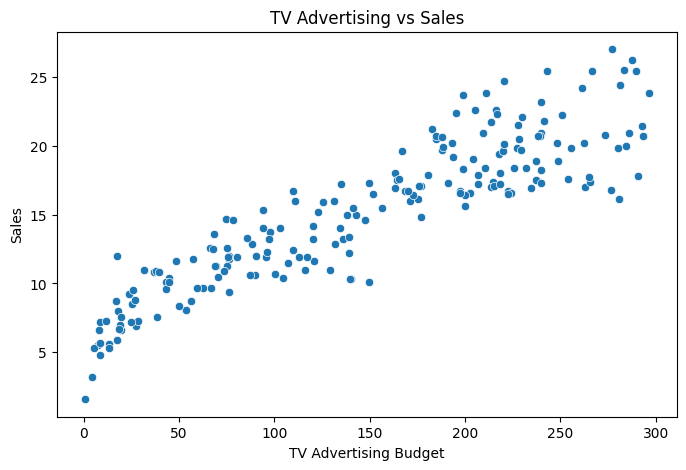

In [50]:
plt.figure(figsize=(8, 5))

sns.scatterplot(data=df, x='TV', y='Sales')

plt.title('TV Advertising vs Sales')
plt.xlabel('TV Advertising Budget')
plt.ylabel('Sales')

plt.show()

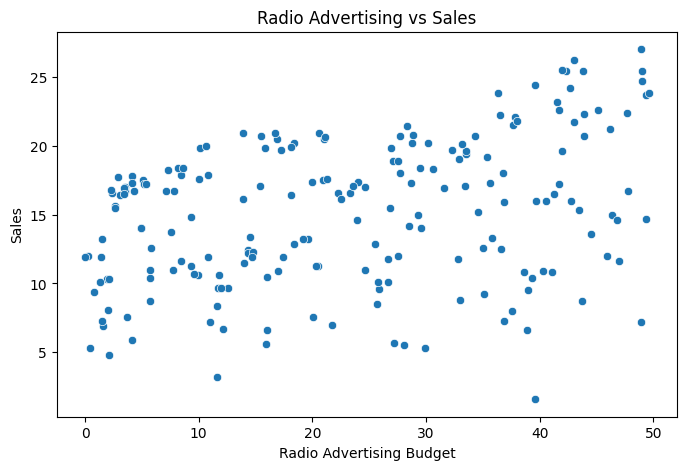

In [51]:
plt.figure(figsize=(8, 5))

sns.scatterplot(data=df, x='Radio', y='Sales')

plt.title('Radio Advertising vs Sales')
plt.xlabel('Radio Advertising Budget')
plt.ylabel('Sales')

plt.show()

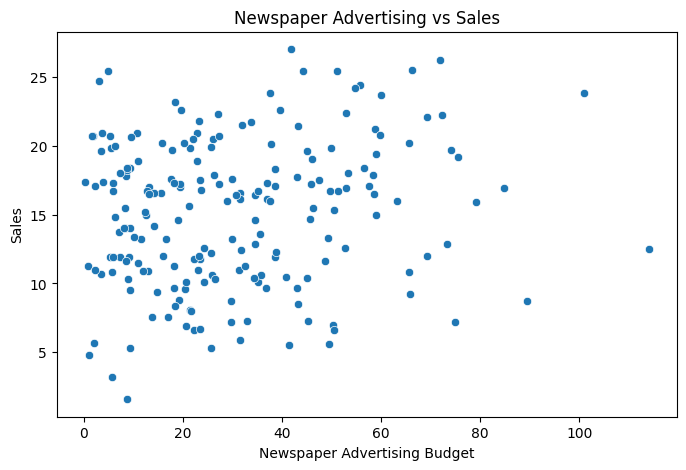

In [52]:
plt.figure(figsize=(8, 5))

sns.scatterplot(data=df, x='Newspaper', y='Sales')

plt.title('Newspaper Advertising vs Sales')
plt.xlabel('Newspaper Advertising Budget')
plt.ylabel('Sales')

plt.show()

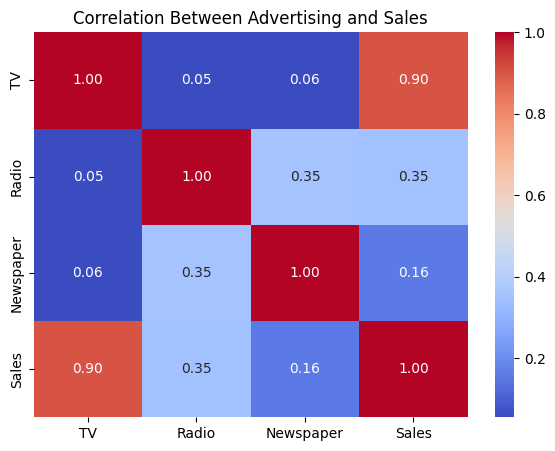

In [53]:
correlation = df.corr(numeric_only=True)

plt.figure(figsize=(7, 5))

sns.heatmap(correlation, annot=True, cmap='coolwarm', fmt='.2f')

plt.title('Correlation Between Advertising and Sales')

plt.show()

## 5. Feature Selection and Train-Test Split

### Feature Selection

The dataset is divided into input features and a target variable.

* **Input Features (X):** TV, Radio, and Newspaper advertising expenditure.
* **Target Variable (y):** Sales, which the models aim to predict.

### Train-Test Split

The dataset is divided into training and testing sets using Scikit-learn's `train_test_split()` function.

* **Training Set:** 160 samples (80%) used to train the models.
* **Testing Set:** 40 samples (20%) used to evaluate model performance.

The split uses `random_state=42` to make the results reproducible. This allows us to evaluate the models on data that was not used during training.


In [54]:
# Select input features
X = df[['TV', 'Radio', 'Newspaper']]

# Select the target variable
y = df['Sales']

print("Features shape:", X.shape)
print("Target shape:", y.shape)

Features shape: (200, 3)
Target shape: (200,)


In [55]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Training samples: 160
Testing samples: 40


## 6. Linear Regression Model

Linear Regression is a supervised machine learning algorithm used to predict a continuous numerical value by learning the relationship between input features and a target variable.

In this project, the model uses TV, Radio, and Newspaper advertising expenditure to predict sales.

### Model Training

The `LinearRegression()` function creates the model, and the `fit()` method trains it using the training dataset (`X_train` and `y_train`).

### Sales Prediction

After training, the `predict()` method generates sales predictions for the testing dataset (`X_test`).

The predicted values are then compared with the actual sales values to evaluate how accurately the model performs.


In [56]:
from sklearn.linear_model import LinearRegression

# Create the model
lr_model = LinearRegression()

# Train the model using training data
lr_model.fit(X_train, y_train)

print("Linear Regression model trained successfully!")

Linear Regression model trained successfully!


In [57]:
# Predict sales using the test data
y_pred = lr_model.predict(X_test)

print("First 10 predicted sales:")
print(y_pred[:10])

First 10 predicted sales:
[17.0347724  20.40974033 23.72398873  9.27278518 21.68271879 12.56940161
 21.08119452  8.69035045 17.23701254 16.66657475]


In [58]:
comparison = pd.DataFrame({
    'Actual Sales': y_test.values,
    'Predicted Sales': y_pred
})

comparison.head(10)

,Actual Sales,Predicted Sales
0,16.9,17.034772
1,22.4,20.409740
2,21.4,23.723989
3,7.3,9.272785
4,24.7,21.682719
5,12.6,12.569402
6,22.3,21.081195
7,8.4,8.690350
8,16.5,17.237013
9,16.1,16.666575


## 7. Linear Regression Model Evaluation

After training the Linear Regression model, we evaluate its predictive performance using three metrics.

* **R² Score:** Measures how well the model explains the variation in actual sales. A higher score generally indicates better predictive performance.
* **Mean Absolute Error (MAE):** Measures the average absolute difference between actual sales and predicted sales. Lower values indicate smaller prediction errors.
* **Root Mean Squared Error (RMSE):** Measures prediction error while giving greater weight to larger errors. Lower values indicate better predictive performance.

These metrics help us understand the accuracy of the Linear Regression model and provide a basis for comparison with the Random Forest model.


In [59]:
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error
import numpy as np

# Calculate evaluation metrics
r2 = r2_score(y_test, y_pred)
mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))

print("Linear Regression Model Evaluation")
print("----------------------------------")
print("R² Score:", round(r2, 4))
print("MAE:", round(mae, 4))
print("RMSE:", round(rmse, 4))

Linear Regression Model Evaluation
----------------------------------
R² Score: 0.9059
MAE: 1.2748
RMSE: 1.7052


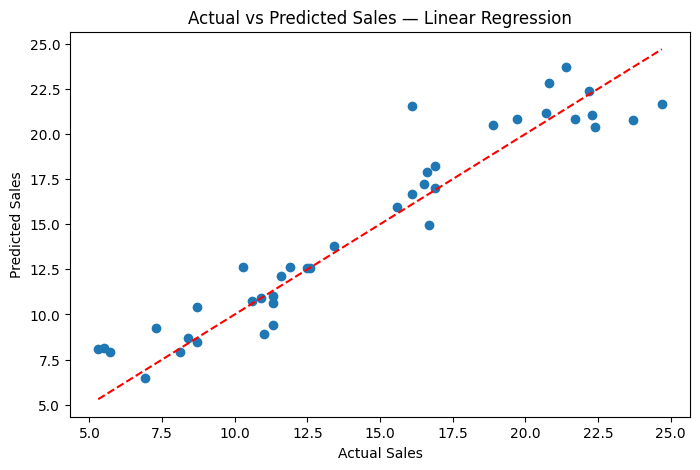

In [60]:
plt.figure(figsize=(8, 5))

plt.scatter(y_test, y_pred)

# Reference line for perfect predictions
lower = min(y_test.min(), y_pred.min())
upper = max(y_test.max(), y_pred.max())

plt.plot([lower, upper], [lower, upper], 'r--')

plt.title('Actual vs Predicted Sales — Linear Regression')
plt.xlabel('Actual Sales')
plt.ylabel('Predicted Sales')

plt.show()

## 8. Random Forest Regression Model

Random Forest Regression is a supervised machine learning algorithm that combines multiple decision trees to predict continuous numerical values.

In this project, the Random Forest model uses TV, Radio, and Newspaper advertising expenditure to predict sales.

### Model Training

The `RandomForestRegressor()` function creates the model. We use 100 decision trees (`n_estimators=100`) to generate predictions and set `random_state=42` to make the results reproducible.

The model is trained using the training dataset (`X_train` and `y_train`).

### Sales Prediction

After training, the model predicts sales for the testing dataset (`X_test`). These predictions are evaluated and compared with those from Linear Regression to determine which model performs better.


In [61]:
from sklearn.ensemble import RandomForestRegressor

# Create the Random Forest model
rf_model = RandomForestRegressor(
    n_estimators=100,
    random_state=42
)

# Train the model
rf_model.fit(X_train, y_train)

print("Random Forest model trained successfully!")

Random Forest model trained successfully!


In [62]:
# Predict sales using Random Forest
y_pred_rf = rf_model.predict(X_test)

print("First 10 Random Forest predictions:")
print(y_pred_rf[:10])

First 10 Random Forest predictions:
[17.299 22.482 19.77   6.784 22.961 13.471 22.595  9.579 16.887 16.793]


## 9. Random Forest Model Evaluation

The Random Forest model is evaluated using the same three metrics as Linear Regression: R² Score, Mean Absolute Error (MAE), and Root Mean Squared Error (RMSE).

### Evaluation Results

* **R² Score: 0.9535** — The model explains approximately 95.35% of the variation in sales on the test dataset.
* **MAE: 0.9180** — The average absolute difference between actual and predicted sales is 0.918 sales units.
* **RMSE: 1.1989** — The root mean squared prediction error is 1.1989 sales units.

These results indicate that the Random Forest model performs well on the test dataset. Its performance will be compared with Linear Regression to identify the better-performing model.


In [63]:
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error
import numpy as np

# Evaluate Random Forest
r2_rf = r2_score(y_test, y_pred_rf)
mae_rf = mean_absolute_error(y_test, y_pred_rf)
rmse_rf = np.sqrt(mean_squared_error(y_test, y_pred_rf))

print("Random Forest Model Evaluation")
print("--------------------------------")
print("R² Score:", round(r2_rf, 4))
print("MAE:", round(mae_rf, 4))
print("RMSE:", round(rmse_rf, 4))

Random Forest Model Evaluation
--------------------------------
R² Score: 0.9535
MAE: 0.918
RMSE: 1.1989


## 10. Model Performance Comparison

In this project, Linear Regression and Random Forest Regression are compared to determine which model predicts sales more accurately.

The models are evaluated using three metrics: R² Score, Mean Absolute Error (MAE), and Root Mean Squared Error (RMSE).

### Comparison Results

| Model             | R² Score |    MAE |   RMSE |
| ----------------- | -------: | -----: | -----: |
| Linear Regression |   0.9059 | 1.2748 | 1.7052 |
| Random Forest     |   0.9535 | 0.9180 | 1.1989 |

### Interpretation

Random Forest performs better than Linear Regression on all three evaluation metrics.

* It achieves a higher R² Score, indicating that it explains more of the variation in sales on the test dataset.
* It has a lower MAE, indicating smaller average absolute prediction errors.
* It has a lower RMSE, indicating smaller prediction errors overall, with greater weight given to larger errors.

Based on these results, Random Forest is the better-performing model on this test split.


In [64]:
comparison_results = pd.DataFrame({
    'Model': ['Linear Regression', 'Random Forest'],
    'R² Score': [r2, r2_rf],
    'MAE': [mae, mae_rf],
    'RMSE': [rmse, rmse_rf]
})

comparison_results = comparison_results.round(4)

display(comparison_results)

,Model,R² Score,MAE,RMSE
0,Linear Regression,0.9059,1.2748,1.7052
1,Random Forest,0.9535,0.9180,1.1989


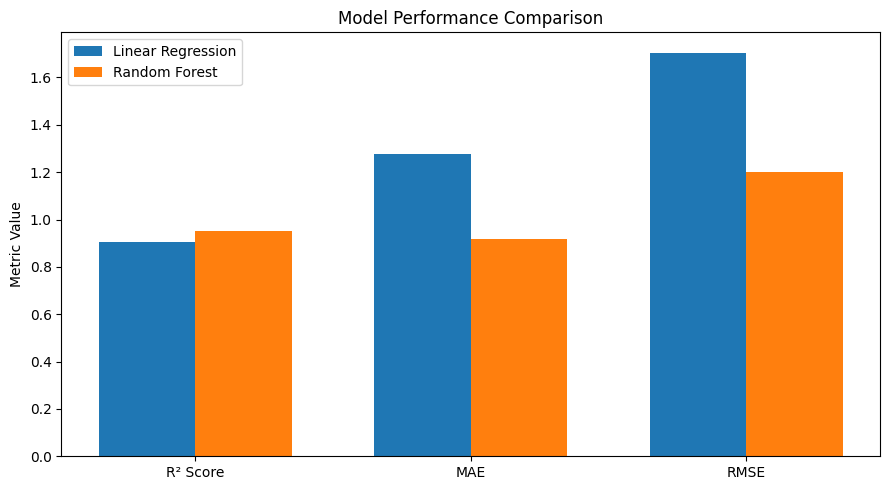

In [65]:
# Compare model performance
metrics = ['R² Score', 'MAE', 'RMSE']

linear_values = [r2, mae, rmse]
forest_values = [r2_rf, mae_rf, rmse_rf]

x = np.arange(len(metrics))
width = 0.35

plt.figure(figsize=(9, 5))

plt.bar(x - width/2, linear_values, width, label='Linear Regression')
plt.bar(x + width/2, forest_values, width, label='Random Forest')

plt.xticks(x, metrics)
plt.title('Model Performance Comparison')
plt.ylabel('Metric Value')
plt.legend()
plt.tight_layout()

plt.show()

## 11. Feature Importance Analysis

Feature importance helps us understand which input variables contribute most to the predictions made by the Random Forest model.

In this project, the feature importance values are used to compare the relative contributions of TV, Radio, and Newspaper advertising expenditure to the model's predictions.

The results are visualized using a bar chart, making it easier to compare the importance of each advertising channel.

### Business Insight

Understanding feature importance can help businesses identify which advertising channels are most influential in the model's sales predictions. These results can inform further analysis of advertising strategies.

Feature importance indicates the model's relative use of each feature; it does not, by itself, prove that a particular advertising channel causes higher sales.


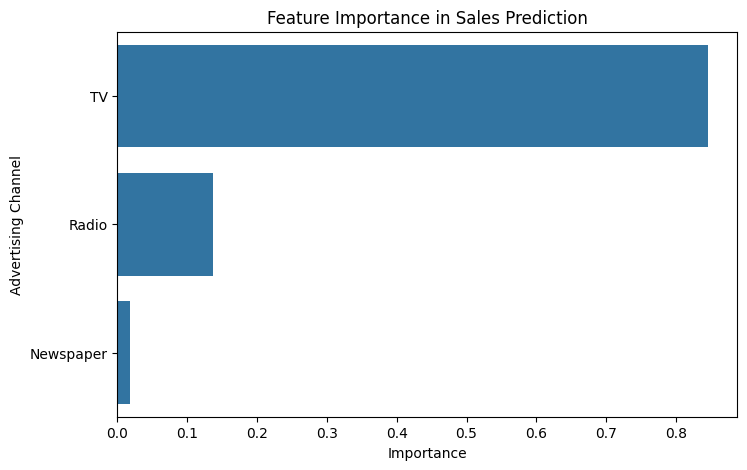

TV           0.845355
Radio        0.136642
Newspaper    0.018003
dtype: float64


In [66]:
importance = pd.Series(
    rf_model.feature_importances_,
    index=X.columns
).sort_values(ascending=False)

plt.figure(figsize=(8, 5))

sns.barplot(x=importance.values, y=importance.index)

plt.title('Feature Importance in Sales Prediction')
plt.xlabel('Importance')
plt.ylabel('Advertising Channel')

plt.show()

print(importance)

## 12. Saving Prediction Results

After training and evaluating the machine learning models, the prediction results are saved to a CSV file for future reference.

The exported file, `Sales_Prediction_Results.csv`, allows the predicted sales values and related results to be stored separately from the notebook.

Saving the results makes it easier to review model predictions, share the output, and use the results in further analysis.

The CSV file can also be uploaded to the project's GitHub repository alongside the notebook.


In [67]:
results = pd.DataFrame({
    'Actual Sales': y_test.values,
    'Linear Regression Predictions': y_pred,
    'Random Forest Predictions': y_pred_rf
})

results.to_csv('Sales_Prediction_Results.csv', index=False)

print("Prediction results saved successfully!")

Prediction results saved successfully!


In [68]:
from google.colab import files

files.download('Sales_Prediction_Results.csv')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

# 13. Conclusion

In this project, machine learning regression techniques were used to predict sales based on advertising expenditure across TV, radio, and newspaper channels.

The Advertising dataset was explored using statistical analysis and visualizations. Two regression models, Linear Regression and Random Forest Regression, were trained and evaluated using R² Score, Mean Absolute Error (MAE), and Root Mean Squared Error (RMSE).

### Key Findings

* Linear Regression achieved an R² Score of 0.9059, an MAE of 1.2748, and an RMSE of 1.7052.
* Random Forest achieved an R² Score of 0.9535, an MAE of 0.9180, and an RMSE of 1.1989.
* Random Forest performed better on all three evaluation metrics for the test dataset.
* Feature importance analysis helped compare the relative contributions of the advertising channels to the Random Forest model's predictions.

### Business Applications

The model can help businesses explore the relationship between advertising expenditure and sales, support advertising-budget analysis, and generate sales estimates from advertising inputs.

### Future Improvements

* Evaluate the models using cross-validation.
* Test additional regression algorithms.
* Tune model parameters to investigate whether predictive performance can be improved.
* Deploy the selected model in an interactive application.

Overall, this project demonstrates how regression models can be used to analyze advertising data and predict sales.
